# A/B Test: which offer sells more, "10% off" or "Free shipping"?

**Context.** An online store shows an offer on the product page. The marketing team wants to replace the classic
*10% off your order* (variant **A**, control) with *Free shipping on orders ≥ €40* (variant **B**).

**Business question.** Does offer B increase conversion **and** profit per visitor enough to justify launching it?

| | Definition |
|---|---|
| **Primary metric** | Conversion rate = buyers / visitors |
| **Secondary metrics** | Revenue per visitor (RPV), average order value (AOV), profit per visitor |
| **Guardrail metrics** | Shipping cost per order, return rate, cancelled orders, checkout latency (see section 2.3) |
| **Hypothesis** | H0: conv(B) = conv(A) · H1: conv(B) ≠ conv(A) (two-sided, α = 0.05, power = 80%) |
| **Randomisation unit** | Visitor, 50/50 split for 28 days |

> The data is **simulated** (`src/generate_data.py`) with a known true effect, so we can check that the analysis recovers it.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
import ab_stats as ab

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

COLORS = {"A": "#2a78d6", "B": "#eb6834"}
LABELS = {"A": "A · 10% off", "B": "B · Free shipping"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "figure.dpi": 110,
})
pd.set_option("display.float_format", "{:,.4f}".format)

df = pd.read_csv(ROOT / "data" / "experiment_data.csv", parse_dates=["date"])
df.head()

,user_id,date,variant,device,user_type,source,converted,revenue,profit
0,1,2026-09-09,A,mobile,new,social,0,0.0000,0.0000
1,2,2026-09-10,B,mobile,returning,organic,0,0.0000,0.0000
2,3,2026-09-04,A,desktop,returning,paid,1,48.4000,16.1300
3,4,2026-09-04,A,mobile,returning,paid,0,0.0000,0.0000
4,5,2026-09-15,B,desktop,returning,organic,1,25.0700,10.0300


## 1. Experiment design: how many visitors do we need?

Before launching the test we set the **minimum detectable effect (MDE)**: the smallest lift that is worth it for the business.
With a historical conversion rate of ~3.6% and a 10% relative MDE, the two-proportion z-test formula gives the sample size per variant.

In [2]:
baseline_cr = 0.036
for mde in [0.05, 0.10, 0.15, 0.20]:
    n = ab.sample_size_proportions(baseline_cr, mde)
    print(f"MDE {mde:>4.0%}  ->  {n:>8,} visitors per variant  ({2 * n:,} in total)")

MDE   5%  ->   172,180 visitors per variant  (344,360 in total)
MDE  10%  ->    44,051 visitors per variant  (88,102 in total)
MDE  15%  ->    20,024 visitors per variant  (40,048 in total)
MDE  20%  ->    11,513 visitors per variant  (23,026 in total)


With a 10% MDE we need **~44,000 visitors per variant**. At ~3,200 visitors/day that is 28 days, which also covers
4 full weeks (avoiding day-of-week bias). **The duration is fixed before starting and the test is not stopped early.**

## 2. Sanity checks

### 2.1 Sample Ratio Mismatch (SRM)
If the actual split deviates from the expected 50/50 more than chance can explain, the assignment is broken (bugs, bots, redirects)
and **no result can be trusted**. We check it with a chi-square test; the alarm goes off at p < 0.001.

In [3]:
counts = df["variant"].value_counts().sort_index()
p_srm = ab.srm_check(counts["A"], counts["B"])
print(counts.to_string())
print(f"\nShare of A: {counts['A'] / counts.sum():.2%}  |  SRM p-value = {p_srm:.3f}")
print("OK: no SRM" if p_srm > 0.001 else "ALERT: possible SRM, check the assignment")

variant
A    45247
B    44753

Share of A: 50.27%  |  SRM p-value = 0.100
OK: no SRM


### 2.2 Covariate balance
Randomisation should split devices, user types and channels evenly. Otherwise, differences could be caused by the traffic mix rather than the offer.

In [4]:
balance = pd.concat(
    {col: pd.crosstab(df[col], df["variant"], normalize="columns") for col in ["device", "user_type", "source"]}
)
balance["diff_pp"] = (balance["B"] - balance["A"]) * 100
balance

variant                  A      B  diff_pp
device    desktop   0.3789 0.3803   0.1434
          mobile    0.6211 0.6197  -0.1434
user_type new       0.6480 0.6510   0.2908
          returning 0.3520 0.3490  -0.2908
source    email     0.1187 0.1204   0.1735
          organic   0.4054 0.3975  -0.7837
          paid      0.2958 0.3051   0.9254
          social    0.1801 0.1770  -0.3151

All differences are below 1 percentage point: the groups are comparable.

### 2.3 Guardrail metrics
A winning offer must not break something else. These metrics are not optimised, but the launch is blocked if they degrade:

| Guardrail | Why it matters for this offer | Threshold to block the launch |
|---|---|---|
| **Shipping cost per order** | B makes the store pay shipping; it could eat the margin | Profit per visitor does not drop (checked in section 4) |
| **Return rate** | Customers who add items just to reach €40 may return them | Increase > 1 pp |
| **Cancelled orders** | Impulse purchases driven by the offer may be cancelled | Increase > 0.5 pp |
| **Checkout latency / errors** | The new shipping logic must not slow down or break checkout | No significant increase |

The simulated dataset only includes profit (which already nets out the shipping cost), so that guardrail is evaluated below.
Returns and cancellations would be tracked 30 days after the experiment ends, since they happen after the purchase.

## 3. Primary metric: conversion rate

In [5]:
summary = df.groupby("variant").agg(
    visitors=("user_id", "size"),
    buyers=("converted", "sum"),
    conversion=("converted", "mean"),
    revenue_per_visitor=("revenue", "mean"),
    profit_per_visitor=("profit", "mean"),
)
summary["avg_order_value"] = df[df.converted == 1].groupby("variant")["revenue"].mean()
summary

,visitors,buyers,conversion,revenue_per_visitor,profit_per_visitor,avg_order_value
variant,,,,,,
A,45247,1625,0.0359,1.6877,0.5626,46.9917
B,44753,1820,0.0407,2.1063,0.7019,51.7925


In [6]:
conv = ab.two_proportion_ztest(
    summary.loc["A", "buyers"], summary.loc["A", "visitors"],
    summary.loc["B", "buyers"], summary.loc["B", "visitors"],
)
print(f"Conversion A: {conv.value_a:.3%}   Conversion B: {conv.value_b:.3%}")
print(f"Absolute difference: {conv.abs_diff * 100:+.2f} pp   95% CI: [{conv.ci_low * 100:+.2f}, {conv.ci_high * 100:+.2f}] pp")
print(f"Relative lift: {conv.rel_lift:+.1%}")
print(f"p-value: {conv.p_value:.5f}  ->  {'significant' if conv.significant else 'not significant'} at α = 0.05")

Conversion A: 3.591%   Conversion B: 4.067%
Absolute difference: +0.48 pp   95% CI: [+0.22, +0.73] pp
Relative lift: +13.2%
p-value: 0.00020  ->  significant at α = 0.05


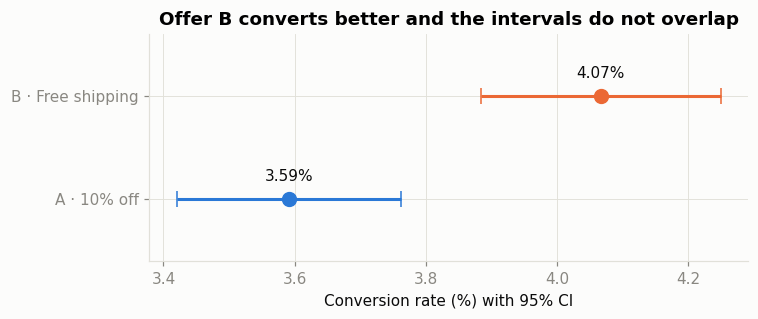

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
for i, v in enumerate(["A", "B"]):
    n, x = summary.loc[v, "visitors"], summary.loc[v, "buyers"]
    p = x / n
    half = 1.96 * np.sqrt(p * (1 - p) / n)
    ax.errorbar(p * 100, i, xerr=half * 100, fmt="o", color=COLORS[v], ms=9, lw=2, capsize=5)
    ax.annotate(f"{p:.2%}", (p * 100, i), xytext=(0, 12), textcoords="offset points", ha="center", color=INK)
ax.set_yticks([0, 1], [LABELS["A"], LABELS["B"]])
ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("Conversion rate (%) with 95% CI")
ax.set_title("Offer B converts better and the intervals do not overlap")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_conversion_ci.png")
plt.show()

## 4. Secondary metrics: do we make more money?

Converting more is not enough: offer B **gives no product discount** but the store **pays for shipping** (€4.90) on orders ≥ €40.
We need to look at revenue and, above all, **profit per visitor**, which captures both effects (and acts as the shipping-cost guardrail).

Revenue per visitor is very skewed (≈96% zeros), so on top of Welch's t-test we compute a **bootstrap CI**, which does not assume normality.

In [8]:
a, b = df[df.variant == "A"], df[df.variant == "B"]
metrics = {
    "Revenue per visitor (€)": "revenue",
    "Profit per visitor (€)": "profit",
}
rows = []
boot_profit = None
for name, col in metrics.items():
    res = ab.welch_ttest(a[col], b[col], metric=name)
    lo, hi, boot = ab.bootstrap_mean_diff(a[col], b[col], n_boot=3_000, seed=1)
    if col == "profit":
        boot_profit = boot
    rows.append([name, res.value_a, res.value_b, res.rel_lift, f"[{res.ci_low:+.3f}, {res.ci_high:+.3f}]", f"[{lo:+.3f}, {hi:+.3f}]", res.p_value])

aov = ab.welch_ttest(a.loc[a.converted == 1, "revenue"], b.loc[b.converted == 1, "revenue"], metric="Average order value (€)")
rows.append([aov.metric, aov.value_a, aov.value_b, aov.rel_lift, f"[{aov.ci_low:+.2f}, {aov.ci_high:+.2f}]", "-", aov.p_value])

secondary = pd.DataFrame(rows, columns=["metric", "A", "B", "lift", "95% CI Welch", "95% CI bootstrap", "p-value"])
secondary.style.format({"A": "{:.3f}", "B": "{:.3f}", "lift": "{:+.1%}", "p-value": "{:.2e}"})

,metric,A,B,lift,95% CI Welch,95% CI bootstrap,p-value
0,Revenue per visitor (€),1.688,2.106,+24.8%,"[+0.278, +0.559]","[+0.273, +0.565]",4.86e-09
1,Profit per visitor (€),0.563,0.702,+24.8%,"[+0.092, +0.186]","[+0.090, +0.188]",6.66e-09
2,Average order value (€),46.992,51.793,+10.2%,"[+3.12, +6.48]",-,2.44e-08


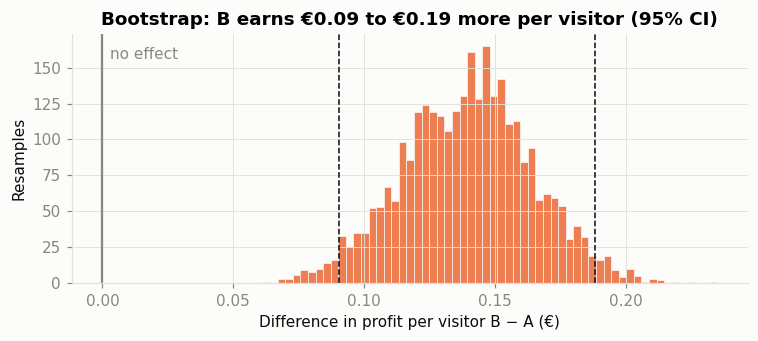

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(boot_profit, bins=60, color=COLORS["B"], alpha=0.85, edgecolor="#fcfcfb", linewidth=0.5)
lo, hi = np.quantile(boot_profit, [0.025, 0.975])
for x in (lo, hi):
    ax.axvline(x, color=INK, ls="--", lw=1)
ax.axvline(0, color=MUTED, lw=1.5)
ax.annotate("no effect", (0, ax.get_ylim()[1] * 0.9), xytext=(5, 0), textcoords="offset points", color=MUTED)
ax.set_xlabel("Difference in profit per visitor B − A (€)")
ax.set_ylabel("Resamples")
ax.set_title(f"Bootstrap: B earns €{lo:.2f} to €{hi:.2f} more per visitor (95% CI)")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_profit_bootstrap.png")
plt.show()

Average order value also goes up in B: some customers **add items to reach the €40** free-shipping threshold.
This offsets the shipping cost and profit per visitor rises by ~25%, so the shipping-cost guardrail is not triggered.

## 5. Bayesian approach

The p-value answers "how likely is this data if there were no effect?". The business usually asks something else:
**"how likely is it that B is better than A?"**. A Beta-Binomial model (uniform prior) answers that directly,
together with the **expected loss**: how much conversion we would lose, on average, if we picked the wrong variant.

In [10]:
bayes = ab.bayesian_proportions(
    summary.loc["A", "buyers"], summary.loc["A", "visitors"],
    summary.loc["B", "buyers"], summary.loc["B", "visitors"],
)
print(f"P(B > A) = {bayes['prob_b_better']:.2%}")
print(f"Expected lift: {bayes['lift_mean']:+.1%}  (95% credible interval: {bayes['lift_ci'][0]:+.1%} to {bayes['lift_ci'][1]:+.1%})")
print(f"Expected loss if we choose A: {bayes['expected_loss_a'] * 100:.4f} pp")
print(f"Expected loss if we choose B: {bayes['expected_loss_b'] * 100:.4f} pp")

P(B > A) = 99.99%
Expected lift: +13.3%  (95% credible interval: +6.1% to +20.9%)
Expected loss if we choose A: 0.4756 pp
Expected loss if we choose B: 0.0000 pp


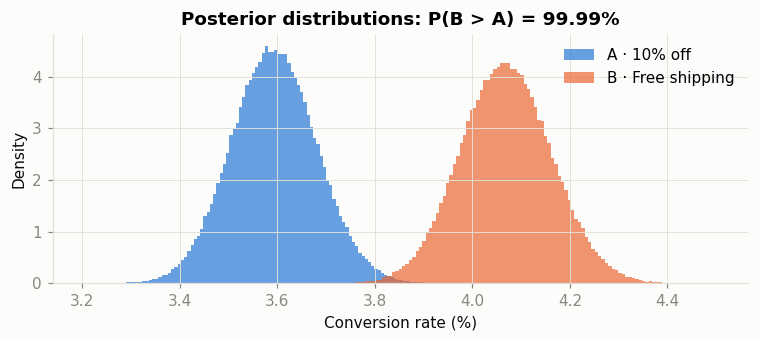

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for v in ["A", "B"]:
    ax.hist(bayes[f"samples_{v.lower()}"] * 100, bins=120, density=True, color=COLORS[v], alpha=0.7, label=LABELS[v])
ax.set_xlabel("Conversion rate (%)")
ax.set_ylabel("Density")
ax.set_title(f"Posterior distributions: P(B > A) = {bayes['prob_b_better']:.2%}")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_bayesian_posterior.png")
plt.show()

## 6. Segment analysis

Is the effect the same for everyone? Running many comparisons raises the chance of a false positive,
so p-values are corrected with **Holm-Bonferroni**. This analysis is **exploratory**: it generates hypotheses, it does not drive the decision.

In [12]:
seg_rows = []
for col in ["device", "user_type", "source"]:
    for level, sub in df.groupby(col):
        g = sub.groupby("variant")["converted"].agg(["sum", "size"])
        r = ab.two_proportion_ztest(g.loc["A", "sum"], g.loc["A", "size"], g.loc["B", "sum"], g.loc["B", "size"])
        seg_rows.append({
            "segment": f"{col} = {level}", "n": len(sub), "conv_A": r.value_a, "conv_B": r.value_b,
            "lift": r.rel_lift, "lift_low": r.ci_low / r.value_a, "lift_high": r.ci_high / r.value_a, "p_value": r.p_value,
        })
segments = pd.DataFrame(seg_rows)
segments["p_holm"] = ab.holm_correction(segments["p_value"])
segments["significant"] = segments["p_holm"] < 0.05
segments.style.format({"n": "{:,}", "conv_A": "{:.2%}", "conv_B": "{:.2%}", "lift": "{:+.1%}",
                       "lift_low": "{:+.1%}", "lift_high": "{:+.1%}", "p_value": "{:.4f}", "p_holm": "{:.4f}"})

,segment,n,conv_A,conv_B,lift,lift_low,lift_high,p_value,p_holm,significant
0,device = desktop,"34,163",4.55%,4.88%,+7.2%,-2.7%,+17.1%,0.1543,0.6171,False
1,device = mobile,"55,837",3.01%,3.57%,+18.7%,+8.9%,+28.6%,0.0002,0.0013,True
2,user_type = new,"58,454",2.95%,3.14%,+6.6%,-2.9%,+16.0%,0.1716,0.6171,False
3,user_type = returning,"31,546",4.78%,5.79%,+21.2%,+10.9%,+31.6%,0.0001,0.0004,True
4,source = email,"10,759",5.21%,5.60%,+7.5%,-8.9%,+23.9%,0.3714,0.6171,False
5,source = organic,"36,133",3.86%,4.08%,+5.6%,-4.9%,+16.0%,0.2949,0.6171,False
6,source = paid,"27,038",2.95%,3.71%,+25.6%,+11.1%,+40.1%,0.0005,0.0033,True
7,source = social,"16,070",2.97%,3.62%,+22.0%,+3.4%,+40.6%,0.0201,0.1005,False


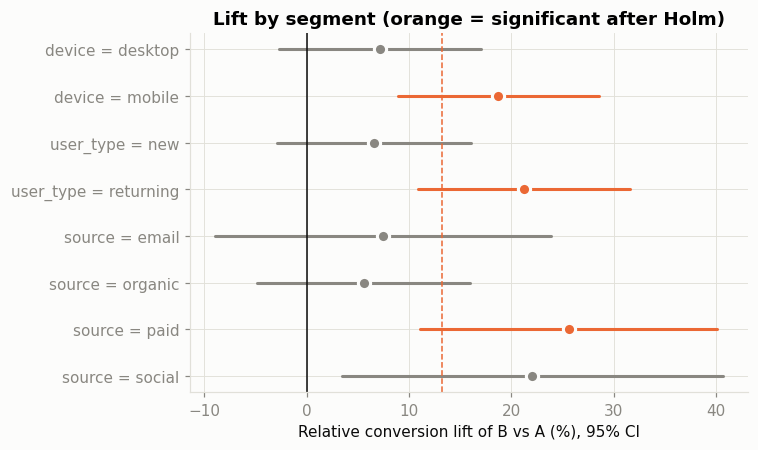

In [13]:
seg = segments.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 4.2))
for i, r in seg.iterrows():
    color = COLORS["B"] if r["significant"] else MUTED
    ax.plot([r["lift_low"] * 100, r["lift_high"] * 100], [i, i], color=color, lw=2, solid_capstyle="round")
    ax.plot(r["lift"] * 100, i, "o", color=color, ms=8, mec="#fcfcfb", mew=2)
ax.axvline(0, color=INK, lw=1)
ax.axvline(conv.rel_lift * 100, color=COLORS["B"], ls="--", lw=1)
ax.annotate("overall lift", (conv.rel_lift * 100, len(seg) - 0.4), xytext=(4, 0), textcoords="offset points", color=INK)
ax.set_yticks(range(len(seg)), seg["segment"])
ax.set_xlabel("Relative conversion lift of B vs A (%), 95% CI")
ax.set_title("Lift by segment (orange = significant after Holm)")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_lift_by_segment.png")
plt.show()

After the Holm correction, **mobile**, **returning users** and **paid traffic** come out significant; for desktop, new users,
email, organic and social the effect is positive but inconclusive.

**Beware of over-interpreting.** Because the data is simulated, we know the truth: the real effect only varies by **device**
(+17% on mobile, +4% on desktop). The differences between returning/new users or between channels are largely **noise**. This is
exactly what happens in real life when data is sliced: "findings" appear that do not replicate. That is why segments are used
to generate hypotheses that are confirmed with a **new test**, never to make decisions with the current one.

## 7. Evolution over time and the danger of *peeking*

Checking results every day and stopping as soon as p < 0.05 greatly inflates the false-positive rate. The chart shows cumulative
conversion: it is very noisy in the first days and stabilises as the sample grows. That is why the duration is fixed in advance.

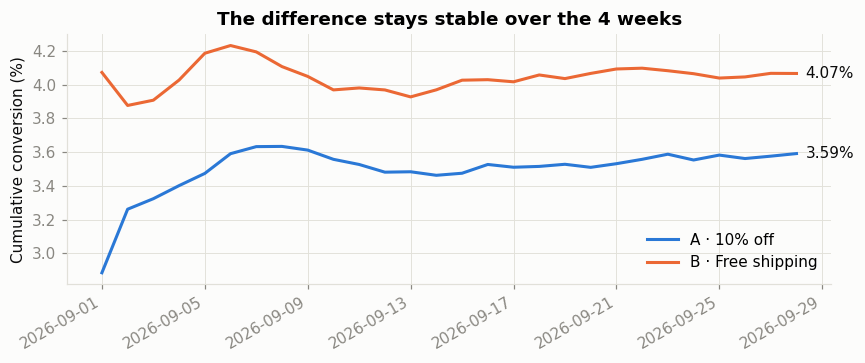

In [14]:
daily = df.groupby(["date", "variant"]).agg(conv=("converted", "sum"), n=("user_id", "size")).unstack("variant")
cum = daily.cumsum()
cum_cr = cum["conv"] / cum["n"] * 100

fig, ax = plt.subplots(figsize=(8, 3.4))
for v in ["A", "B"]:
    ax.plot(cum_cr.index, cum_cr[v], color=COLORS[v], lw=2, label=LABELS[v])
    ax.annotate(f"{cum_cr[v].iloc[-1]:.2f}%", (cum_cr.index[-1], cum_cr[v].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK)
ax.set_ylabel("Cumulative conversion (%)")
ax.set_title("The difference stays stable over the 4 weeks")
ax.legend(frameon=False, loc="lower right")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIG_DIR / "05_cumulative_conversion.png")
plt.show()

## 8. Estimated business impact

In [15]:
monthly_visitors = 3_200 * 30
profit_a = summary.loc["A", "profit_per_visitor"]
profit_b = summary.loc["B", "profit_per_visitor"]
lo, hi = np.quantile(boot_profit, [0.025, 0.975])
print(f"Estimated monthly profit with A: €{profit_a * monthly_visitors:,.0f}")
print(f"Estimated monthly profit with B: €{profit_b * monthly_visitors:,.0f}")
print(f"Incremental profit: {(profit_b - profit_a) * monthly_visitors:+,.0f} €/month "
      f"(95% CI: {lo * monthly_visitors:+,.0f} € to {hi * monthly_visitors:+,.0f} €)")

Estimated monthly profit with A: €54,005
Estimated monthly profit with B: €67,384
Incremental profit: +13,379 €/month (95% CI: +8,686 € to +18,050 €)


## 9. Conclusion and recommendation

| Question | Answer |
|---|---|
| Is the experiment valid? | Yes: no SRM and balanced groups |
| Does B convert better? | Yes: **+13% relative lift** (p < 0.001), 95% CI of the difference entirely positive |
| Does B make more money? | Yes: revenue and **profit per visitor +25%**, despite absorbing the shipping cost |
| What does the Bayesian approach say? | P(B > A) ≈ 100% and the expected loss of choosing B is practically zero |
| Who does it work for? | Mainly **mobile**; not enough evidence on desktop (exploratory analysis) |
| Guardrails? | Shipping cost is covered (profit up). Returns and cancellations to be monitored for 30 days after launch |

**Recommendation: roll out the "Free shipping on orders ≥ €40" offer to 100% of traffic.**

Next steps:
1. Monitor profit per visitor, returns and cancellations after launch (possible novelty effect, items added only to reach €40).
2. Test the free-shipping threshold (€35 vs €40 vs €50), since it is what drives the average order value.
3. On desktop, test alternative offers, since free shipping shows no clear effect there.

**Method validation:** the data was simulated with a true lift of +17% on mobile and +4% on desktop. The analysis recovers
that pattern (strong effect on mobile, weak and non-significant on desktop) and estimates an overall lift (+13%) consistent with the truth.
It also illustrates a risk: some segments with no real differential effect (returning users, paid traffic) come out significant by chance.